In [4]:
import pandas as pd


In [6]:
df = pd.read_csv("../dataset/crop_data.csv")

In [7]:
df.head()


,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice


In [9]:
df.shape


(2200, 8)

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   str    
dtypes: float64(4), int64(3), str(1)
memory usage: 153.0 KB


In [11]:
df.isnull().sum()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

In [13]:
df.duplicated().sum()

np.int64(0)

In [15]:
df.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [22]:
crop_counts = df["label"].value_counts()
print(crop_counts)

label
rice           100
maize          100
chickpea       100
kidneybeans    100
pigeonpeas     100
mothbeans      100
mungbean       100
blackgram      100
lentil         100
pomegranate    100
banana         100
mango          100
grapes         100
watermelon     100
muskmelon      100
apple          100
orange         100
papaya         100
coconut        100
cotton         100
jute           100
coffee         100
Name: count, dtype: int64


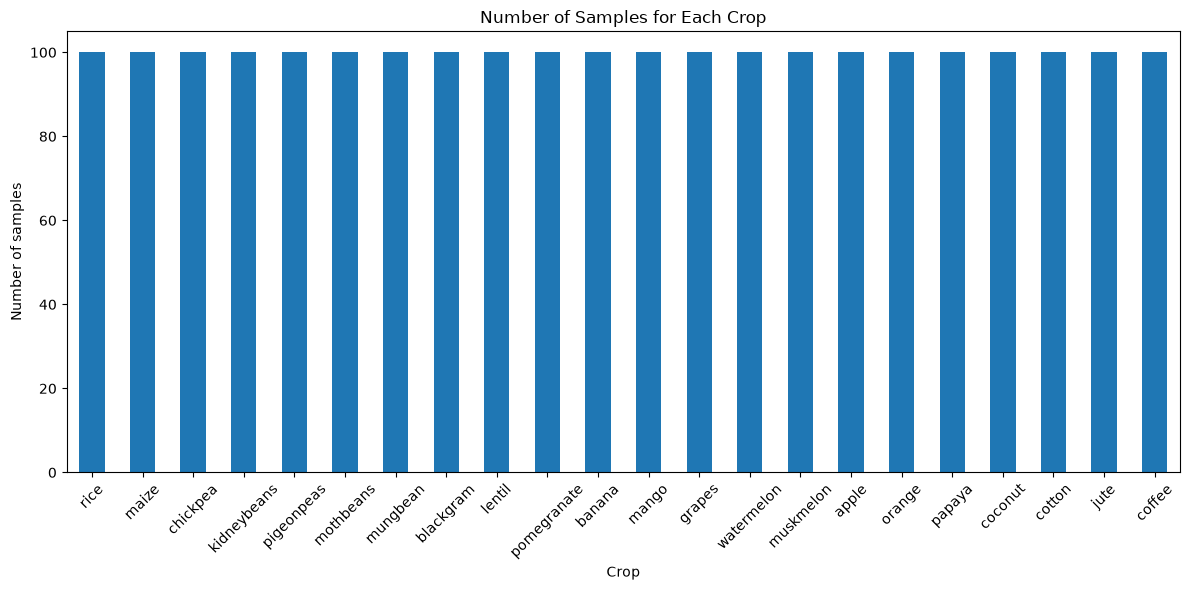

In [29]:
import matplotlib.pyplot as plt
crop_counts = df["label"].value_counts()
crop_counts.plot(kind="bar",figsize=(12,6))
plt.title("Number of Samples for Each Crop")
plt.xlabel("Crop")
plt.ylabel("Number of samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

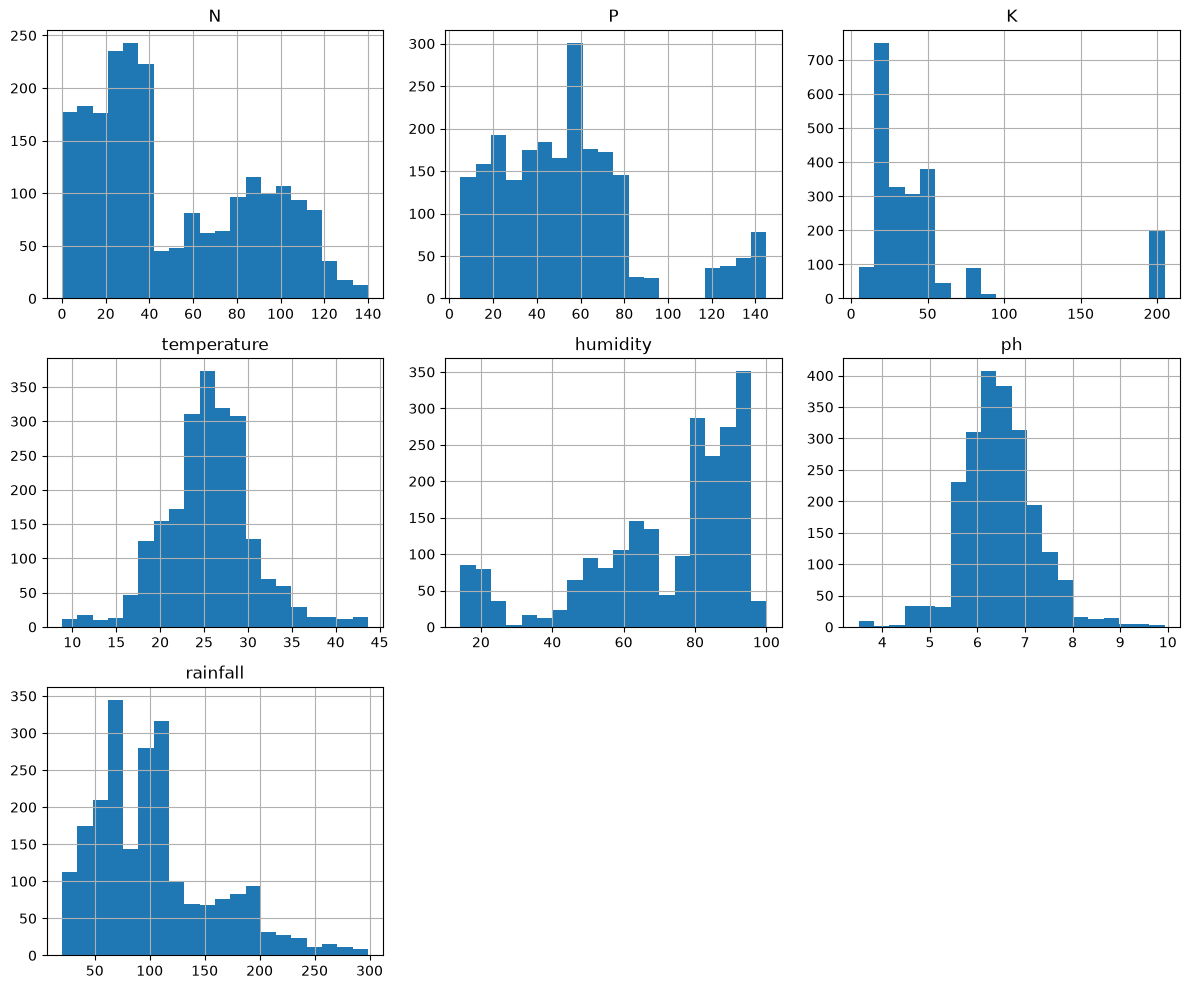

In [30]:
import matplotlib.pyplot as plt
numerical_features = df[["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]]
numerical_features.hist(figsize=(12, 10),bins=20)
plt.tight_layout()
plt.show()

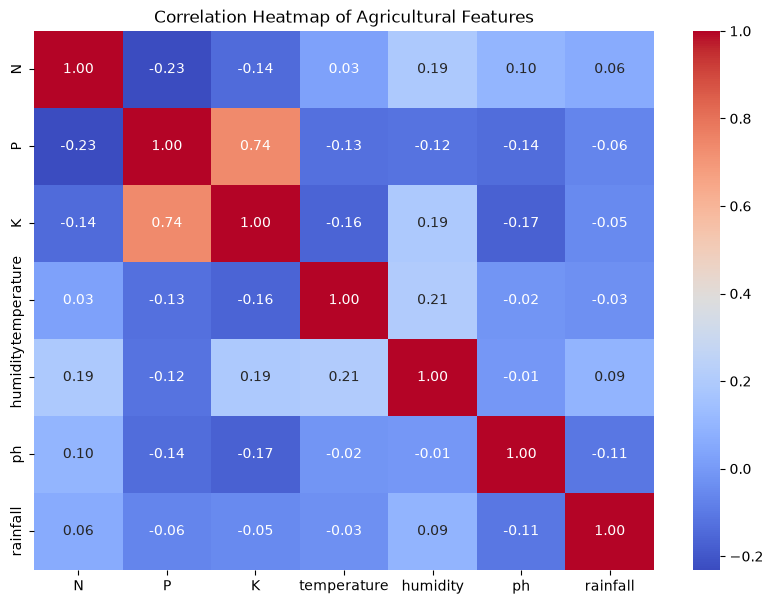

In [33]:
correlation = numerical_features.corr()
plt.figure(figsize=(10,7))
import seaborn as sns
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Heatmap of Agricultural Features")
plt.show()

In [34]:
# Select the 7 input features
X = df[["N", "P", "K", "temperature", "humidity", "ph", "rainfall"]]

# Select the target column
y = df["label"]

# Display the shape of the input data
print("X shape:", X.shape)

# Display the shape of the target data
print("y shape:", y.shape)

X shape: (2200, 7)
y shape: (2200,)


In [35]:
# Import the function used to split the dataset
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display the shape of the training input data
print("X_train shape:", X_train.shape)

# Display the shape of the testing input data
print("X_test shape:", X_test.shape)

# Display the shape of the training target data
print("y_train shape:", y_train.shape)

# Display the shape of the testing target data
print("y_test shape:", y_test.shape)

X_train shape: (1760, 7)
X_test shape: (440, 7)
y_train shape: (1760,)
y_test shape: (440,)


In [36]:
# Import the Decision Tree classification algorithm
from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model
decision_tree = DecisionTreeClassifier(random_state=42)

# Train the model using the training data
decision_tree.fit(X_train, y_train)

# Make predictions using the testing data
y_pred_dt = decision_tree.predict(X_test)

# Display a few predictions
print(y_pred_dt[:10])

['orange' 'banana' 'cotton' 'maize' 'orange' 'chickpea' 'rice' 'blackgram'
 'banana' 'orange']


In [37]:
# Import the accuracy score function
from sklearn.metrics import accuracy_score

# Calculate the accuracy of the Decision Tree model
dt_accuracy = accuracy_score(y_test, y_pred_dt)

# Display the accuracy
print("Decision Tree Accuracy:", dt_accuracy)

Decision Tree Accuracy: 0.9795454545454545


In [38]:
# Import the classification report function
from sklearn.metrics import classification_report

# Generate the classification report
report_dt = classification_report(y_test, y_pred_dt)

# Display the classification report
print(report_dt)

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.80      0.89        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      0.95      0.95        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       0.86      0.90      0.88        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       0.86      0.95      0.90        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

In [39]:
# Import the K-Nearest Neighbors classification algorithm
from sklearn.neighbors import KNeighborsClassifier

# Create the KNN model
knn = KNeighborsClassifier(n_neighbors=5)

# Train the KNN model using the training data
knn.fit(X_train, y_train)

# Make predictions using the testing data
y_pred_knn = knn.predict(X_test)

# Calculate the KNN accuracy
knn_accuracy = accuracy_score(y_test, y_pred_knn)

# Display the KNN accuracy
print("KNN Accuracy:", knn_accuracy)

KNN Accuracy: 0.9772727272727273


In [40]:
# Import the Random Forest classification algorithm
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model with 100 decision trees
random_forest = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Train the Random Forest model
random_forest.fit(X_train, y_train)

# Make predictions using the testing data
y_pred_rf = random_forest.predict(X_test)

# Calculate the Random Forest accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)

# Display the Random Forest accuracy
print("Random Forest Accuracy:", rf_accuracy)

Random Forest Accuracy: 0.9954545454545455


In [41]:
# Import the classification report function
from sklearn.metrics import classification_report

# Generate the classification report for Random Forest
rf_report = classification_report(y_test, y_pred_rf)

# Display the classification report
print(rf_report)

              precision    recall  f1-score   support

       apple       1.00      1.00      1.00        20
      banana       1.00      1.00      1.00        20
   blackgram       1.00      0.95      0.97        20
    chickpea       1.00      1.00      1.00        20
     coconut       1.00      1.00      1.00        20
      coffee       1.00      1.00      1.00        20
      cotton       1.00      1.00      1.00        20
      grapes       1.00      1.00      1.00        20
        jute       0.95      1.00      0.98        20
 kidneybeans       1.00      1.00      1.00        20
      lentil       1.00      1.00      1.00        20
       maize       0.95      1.00      0.98        20
       mango       1.00      1.00      1.00        20
   mothbeans       1.00      1.00      1.00        20
    mungbean       1.00      1.00      1.00        20
   muskmelon       1.00      1.00      1.00        20
      orange       1.00      1.00      1.00        20
      papaya       1.00    

In [42]:
# Get the importance of each input feature from the Random Forest
feature_importance = pd.Series(
    random_forest.feature_importances_,
    index=X.columns
)

# Sort the features from most important to least important
feature_importance = feature_importance.sort_values(ascending=False)

# Display the feature importance values
print(feature_importance)

rainfall       0.230184
humidity       0.224227
K              0.175393
P              0.150850
N              0.096363
temperature    0.072375
ph             0.050608
dtype: float64


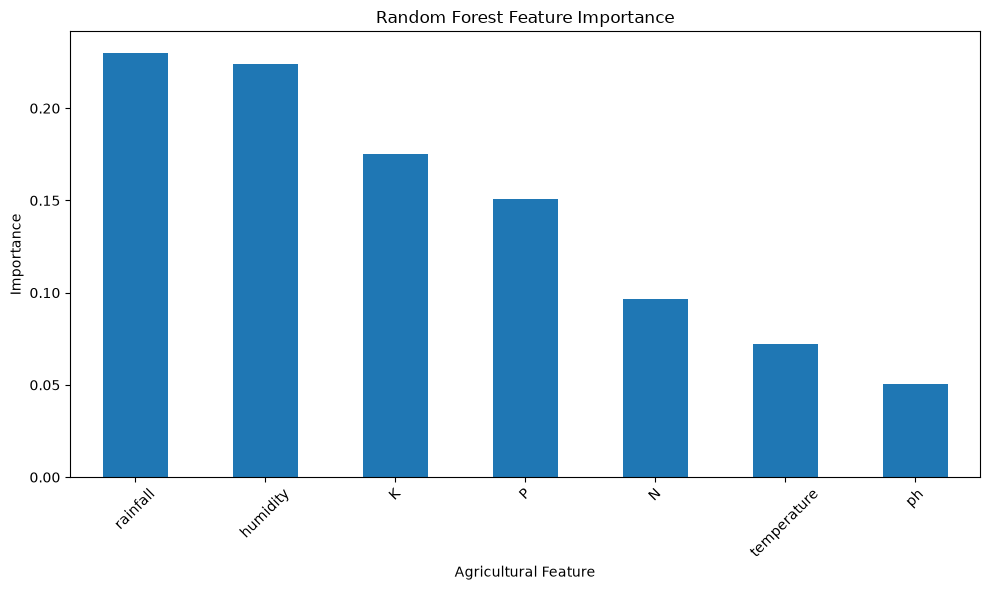

In [43]:
# Create a bar chart for feature importance
feature_importance.plot(
    kind="bar",
    figsize=(10, 6)
)

# Add a title to the graph
plt.title("Random Forest Feature Importance")

# Add the x-axis label
plt.xlabel("Agricultural Feature")

# Add the y-axis label
plt.ylabel("Importance")

# Rotate the feature names for better readability
plt.xticks(rotation=45)

# Adjust the spacing of the graph
plt.tight_layout()

# Display the graph
plt.show()

In [44]:
# Create sample agricultural input values
sample_input = pd.DataFrame({
    "N": [90],
    "P": [42],
    "K": [43],
    "temperature": [25.5],
    "humidity": [80],
    "ph": [6.5],
    "rainfall": [200]
})

# Display the sample input
print(sample_input)

    N   P   K  temperature  humidity   ph  rainfall
0  90  42  43         25.5        80  6.5       200


In [45]:
# Use the Random Forest model to predict the crop
predicted_crop = random_forest.predict(sample_input)

# Display the predicted crop
print("Recommended Crop:", predicted_crop[0])

Recommended Crop: rice


In [46]:
# Get the probability of each crop for the sample input
probabilities = random_forest.predict_proba(sample_input)[0]

# Get the names of all crops
crop_names = random_forest.classes_

# Combine crop names with their probabilities
crop_probabilities = pd.Series(
    probabilities,
    index=crop_names
)

# Sort the probabilities from highest to lowest
crop_probabilities = crop_probabilities.sort_values(
    ascending=False
)

# Display all crop probabilities
print(crop_probabilities)

rice           0.53
jute           0.46
watermelon     0.01
blackgram      0.00
apple          0.00
banana         0.00
coffee         0.00
coconut        0.00
chickpea       0.00
cotton         0.00
lentil         0.00
maize          0.00
grapes         0.00
kidneybeans    0.00
mothbeans      0.00
mango          0.00
mungbean       0.00
muskmelon      0.00
papaya         0.00
orange         0.00
pomegranate    0.00
pigeonpeas     0.00
dtype: float64


In [47]:
# Select the top 3 crop recommendations
top_3_crops = crop_probabilities.head(3)

# Display the top 3 crops
print("Top 3 Crop Recommendations:")
print(top_3_crops)

Top 3 Crop Recommendations:
rice          0.53
jute          0.46
watermelon    0.01
dtype: float64


In [48]:
# Import the joblib library
import joblib

# Save the trained Random Forest model
joblib.dump(random_forest, "../model/crop_model.pkl")

# Confirm that the model was saved
print("Random Forest model saved successfully!")

Random Forest model saved successfully!
